In [1]:
from sklearn.metrics import roc_curve, auc
import pandas as pd
import numpy as np
from sklearn import metrics
import os
def bootstrap_95CI(y_true,y_prob,n_bootstraps):
    rng_seed = 42  # reproducibility
    tprs = []
    base_fpr = np.linspace(0, 1, 101)
    aucs = []
    
    # Run the bootstrap
    rng = np.random.RandomState(rng_seed)
    for i in range(n_bootstraps):
        # Bootstrap by sampling with replacement on the prediction indices
        indices = rng.randint(0, len(y_prob), len(y_prob))
        if len(np.unique(y_true[indices])) < 2:
            # We need at least one positive and one negative sample for AUC
            continue
    
        fpr, tpr, _ = roc_curve(y_true[indices], y_prob[indices])
        roc_auc_boostrap = auc(fpr, tpr)
        aucs.append(roc_auc_boostrap)
        tpr = np.interp(base_fpr, fpr, tpr)
        tpr[0] = 0.0
        tprs.append(tpr)
    
    # Calculate mean and standard deviation of tprs
    tprs = np.array(tprs)
    tprs_upper = np.percentile(tprs, 97.5, axis=0)
    tprs_lower = np.percentile(tprs, 2.5, axis=0)

    aucs = np.array(aucs)
    aucs_upper = np.percentile(aucs, 97.5, axis=0)
    aucs_lower = np.percentile(aucs, 2.5, axis=0)

    # Original ROC curve
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_auc = auc(fpr, tpr)
    
    output = dict()
    output['fpr'] = fpr.copy()
    output['tpr'] = tpr.copy()
    output['auc'] = roc_auc
    output['auc_lower'] = aucs_lower
    output['auc_upper'] = aucs_upper
    output['base_fpr'] = base_fpr.copy()
    output['tprs_lower'] = tprs_lower.copy()
    output['tprs_upper'] = tprs_upper.copy()
    return output,aucs

In [29]:
# external
outcomes = pd.read_csv('data/processed/external_bwh_Y.csv',index_col=0)
outcomes = outcomes.iloc[:,1:]
RF_probs = pd.read_csv('results/postsurgery_model/probs_topn_features_external_bwh.csv',index_col=0)
pre_probs = pd.read_csv('results/preop_model/probs_preop_features_external_bwh.csv', index_col=0)
sts_probs = pd.read_csv('data/processed/external_bwh_stspred.csv',index_col=0)
sts_probs = sts_probs[['predmort','predstro','predrenf','predvent','predreop','predmm','pred14d','pred6d']]
AEnames = outcomes.columns
sts_probs.columns = AEnames

savepath = 'outputs/figure2/external_bwh'
if not os.path.exists(savepath):
    os.makedirs(savepath)

In [38]:
# retrospective MMC
outcomes = pd.read_csv('data/processed/internal_Ytest.csv',index_col=0)
outcomes = outcomes.reset_index(drop=True)
RF_probs = pd.read_csv('results/postsurgery_model/probs_topn_features_internal.csv',index_col=0)
pre_probs = pd.read_csv('results/preop_model/probs_preop_features_internal.csv', index_col=0)
sts_probs = pd.read_csv('data/processed/internal_stspred_test.csv')
sts_probs.columns = sts_probs.columns.str.lower()
sts_probs = sts_probs[['predmort','predstro','predrenf','predvent','predreop','predmm','pred14d','pred6d']]
AEnames = outcomes.columns
sts_probs.columns = AEnames

savepath = 'outputs/figure2/internal'
if not os.path.exists(savepath):
    os.makedirs(savepath)

In [34]:
# prospective MMC
outcomes = pd.read_csv('data/processed/temporal_Y.csv',index_col=0)
outcomes = outcomes.reset_index(drop=True)
RF_probs = pd.read_csv('results/postsurgery_model/probs_topn_features_temporal.csv',index_col=0)
pre_probs = pd.read_csv('results/preop_model/probs_preop_features_temporal.csv', index_col=0)
sts_probs = pd.read_csv('data/processed/temporal_stspred.csv')
sts_probs.columns = sts_probs.columns.str.lower()
sts_probs = sts_probs[['predmort','predstro','predrenf','predvent','predreop','predmm','pred14d','pred6d']]
AEnames = outcomes.columns
sts_probs.columns = AEnames

savepath = 'outputs/figure2/temporal'
if not os.path.exists(savepath):
    os.makedirs(savepath)

In [39]:
# test set bootstrap
n_bootstraps = 10000
outs = dict()
aucs = dict()
for AE in AEnames:
    outs[AE],aucs[AE] = bootstrap_95CI(outcomes[AE].values,RF_probs[AE],n_bootstraps)

n_bootstraps = 10000
preouts = dict()
preaucs = dict()
for AE in AEnames:
    preouts[AE],preaucs[AE] = bootstrap_95CI(outcomes[AE].values,pre_probs[AE],n_bootstraps)

n_bootstraps = 10000
STSouts = dict()
STSaucs = dict()
for AE in AEnames:
    y_true = outcomes.loc[sts_probs[AE].notna(),AE].values
    y_prob = sts_probs.loc[sts_probs[AE].notna(),AE].values
    STSouts[AE], STSaucs[AE] = bootstrap_95CI(y_true,y_prob,n_bootstraps)


In [40]:
def calc_pvalue(aucs1,aucs2,filename):
    empirical_results = []

    for AE in AEnames:
        rf_boot = np.array(aucs1[AE])
        sts_boot = np.array(aucs2[AE])

        n = min(len(rf_boot), len(sts_boot))
        diffs = rf_boot[:n] - sts_boot[:n]
        mean_diff = np.mean(diffs)
        ci_diff = (np.percentile(diffs, 2.5), np.percentile(diffs, 97.5))

        one_sided_p = np.mean(diffs <= 0)

        empirical_results.append({
            'AE': AE,
            'Mean AUC Diff (RF - STS)': round(mean_diff, 3),
            '95% CI of Diff': f"({ci_diff[0]:.3f}, {ci_diff[1]:.3f})",
            'p value (one-sided)': round(one_sided_p, 4),
            # 't test p-value': round(pval_ttest, 4),
            # 't test U-value': round(pval_mwu, 4)
        })

    empirical_df = pd.DataFrame(empirical_results)
    empirical_df.to_csv(savepath+'/'+filename+'.csv', index=False)

calc_pvalue(aucs,STSaucs,'intra_sts_statistics')
calc_pvalue(aucs,preaucs,'intra_pre_statistics')
calc_pvalue(preaucs,STSaucs,'pre_sts_statistics')

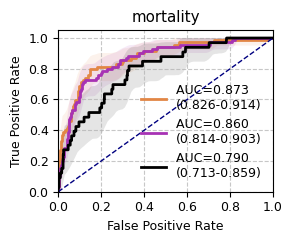

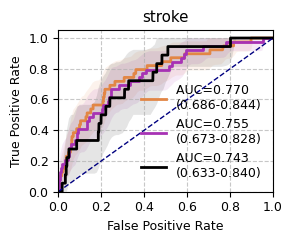

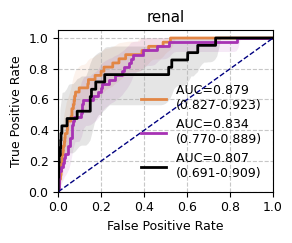

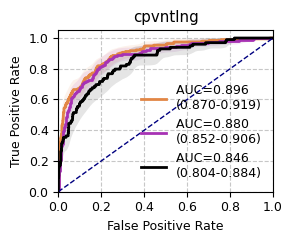

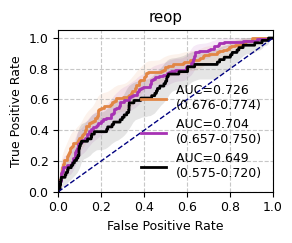

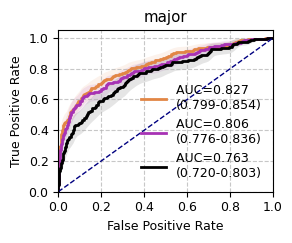

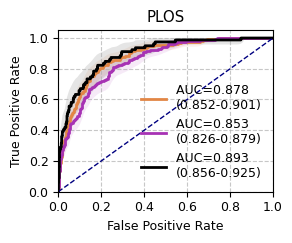

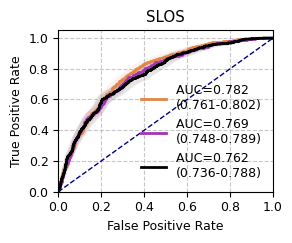

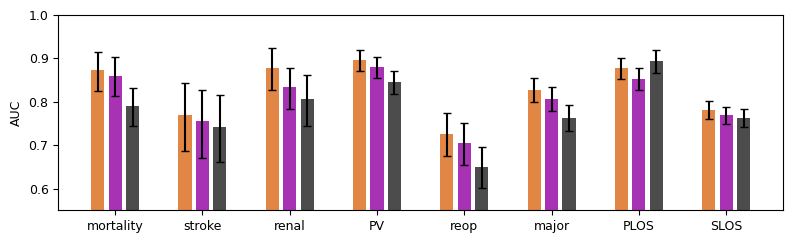

In [41]:
import matplotlib.pyplot as plt
import matplotlib as mpl

for AE in AEnames:
    plt.subplots(figsize=(3,2.5))
    mpl.rcParams['font.size'] = 9
    # AE = 'major'
    out_AE = outs[AE]
    roc_auc = out_AE['auc']
    roc_auc_lower = out_AE['auc_lower']
    roc_auc_upper = out_AE['auc_upper']
    plt.plot(out_AE['fpr'], out_AE['tpr'], color='#e28645', lw=2, label=f'AUC={roc_auc:.3f} \n({roc_auc_lower:.3f}-{roc_auc_upper:.3f})')
    plt.fill_between(out_AE['base_fpr'], out_AE['tprs_lower'], out_AE['tprs_upper'], color='#e28645', alpha=0.1,label=None,edgecolor=None)


    preout_AE = preouts[AE]
    roc_auc = preout_AE['auc']
    roc_auc_lower = preout_AE['auc_lower']
    roc_auc_upper = preout_AE['auc_upper']
    plt.plot(preout_AE['fpr'], preout_AE['tpr'], color="#a732b4", lw=2, label=f'AUC={roc_auc:.3f} \n({roc_auc_lower:.3f}-{roc_auc_upper:.3f})')
    plt.fill_between(preout_AE['base_fpr'], preout_AE['tprs_lower'], preout_AE['tprs_upper'], color="#a732b4", alpha=0.1,
                     label=None,edgecolor=None)
    
    STSout_AE = STSouts[AE]
    roc_auc = STSout_AE['auc']
    roc_auc_lower = STSout_AE['auc_lower']
    roc_auc_upper = STSout_AE['auc_upper']
    plt.plot(STSout_AE['fpr'], STSout_AE['tpr'], color='black', lw=2, label=f'AUC={roc_auc:.3f} \n({roc_auc_lower:.3f}-{roc_auc_upper:.3f})')
    plt.fill_between(STSout_AE['base_fpr'], STSout_AE['tprs_lower'], STSout_AE['tprs_upper'], color='black', alpha=0.1,
                     label=None,edgecolor=None)
    
    
    plt.plot([0, 1], [0, 1], linestyle='--', color='navy', lw=1)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.grid(True, linestyle='--', alpha=0.7)
    
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    # plt.title('Receiver Operating Characteristic with Bootstrap Confidence Intervals')
    plt.legend(loc="lower right")
    plt.legend(frameon=False)

    plt.title(AE)
    plt.tight_layout()

    plt.savefig(savepath+'/test_'+AE+'.jpg', format='jpg', dpi=300)

# barplot with 95%CI.

df_auc_test = dict()
for AE in AEnames:
    scores = dict()
    scores['Roux'] = outs[AE]['auc']
    scores['Roux_lower'] = outs[AE]['auc_lower']
    scores['Roux_upper'] = outs[AE]['auc_upper']

    scores['Pre'] = preouts[AE]['auc']
    scores['Pre_lower'] = preouts[AE]['auc_lower']
    scores['Pre_upper'] = preouts[AE]['auc_upper']

    scores['STS'] = STSouts[AE]['auc']
    scores['STS_lower'] = STSouts[AE]['auc_lower']
    scores['STS_upper'] = STSouts[AE]['auc_upper']
    df_auc_test[AE] = scores
df_auc_test = pd.DataFrame(df_auc_test).T

errors1 = [df_auc_test['Roux'] - df_auc_test['Roux_lower'], df_auc_test['Roux_upper'] - df_auc_test['Roux']]
errors2 = [df_auc_test['Pre'] - df_auc_test['Pre_lower'], df_auc_test['Pre_upper'] - df_auc_test['Pre']]
errors3 = [df_auc_test['STS'] - df_auc_test['STS_lower'], df_auc_test['STS_upper'] - df_auc_test['STS']]
# Create the barplot
fig, ax = plt.subplots(figsize=(8,2.5))
mpl.rcParams['font.size'] = 9
# Plot the bars with error bars
bar_width = 0.15
# index = df_auc_test.index
index = np.arange(len(df_auc_test))

bars1 = ax.bar(index-0.2, df_auc_test['Roux'], bar_width, yerr=errors1, label='Post-surgery', capsize=3,color='#e28645',alpha=1)
bars2 = ax.bar(index, df_auc_test['Pre'], bar_width, yerr=errors1, label='Preop', capsize=3,color='#a732b4',alpha=1)
bars3 = ax.bar(index+0.2, df_auc_test['STS'], bar_width, yerr=errors2, label='STS model', capsize=3,color='black',alpha=0.7)

# Add labels and title
ax.set_ylabel('AUC')
# ax.legend('upper right')
ax.set_xticks(index)
ax.set_yticks([0.6,0.7,0.8,0.9,1])

ax.set_xticklabels(['mortality', 'stroke', 'renal', 'PV', 'reop', 'major', 'PLOS','SLOS'])
ax.set_ylim([0.55,1])
plt.tight_layout()
plt.savefig(savepath+'/test_comparsion.jpg', format='jpg', dpi=300)
plt.show()
